<a href="https://colab.research.google.com/github/loveyourz-s/CV-scanner/blob/main/ScannerProject(KuresbayAkbotaDS_23b).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
import time

На этом этапе загружается исходную фотографию документа под наклоном, перевожу ее в градацию серого (Grayscale) для уменьшения объема данных и применяется размытие по Гауссу для устранения шумов и мелких артефактов фона.

Успешно загружено за 632.44 мс!


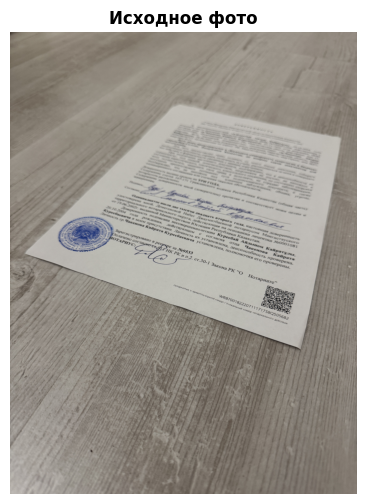

Время предобработки (Gray + Blur): 54.56 мс


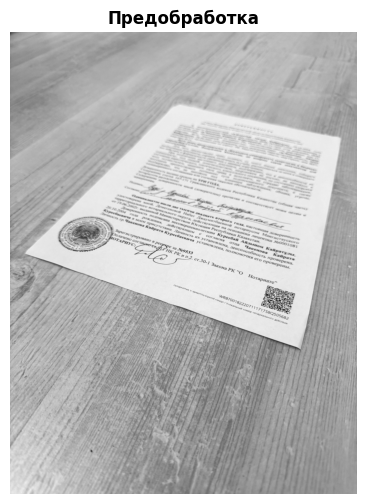

In [12]:
filename = 'IMG_0259.JPG'

# Замер времени загрузки
t_start = time.time()
image = cv2.imread(filename)
t_load = (time.time() - t_start) * 1000

if image is None:
    print(f"Ошибка: Файл '{filename}' не найден!")
else:
    print(f"Успешно загружено за {t_load:.2f} мс!")

    def show_image(img, title=""):
        plt.figure(figsize=(6, 6))
        if len(img.shape) == 3:
            plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        else:
            plt.imshow(img, cmap='gray')
        plt.title(title, fontweight='bold')
        plt.axis('off')
        plt.show()

    show_image(image, "Исходное фото")

    # Замер времени предобработки
    t_start = time.time()
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)
    t_blur = (time.time() - t_start) * 1000
    print(f"Время предобработки (Gray + Blur): {t_blur:.2f} мс")

    show_image(blurred, "Предобработка")

Здесь сначала использую стандартный алгоритм Canny и морфологическое расширение (`dilate`) для поиска границ. Но этот метод слишком чувствителен к текстуре пола и фона, что создает много лишних линий и усложняет поиск контура документа.

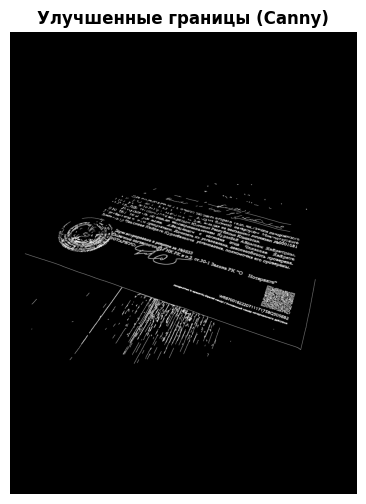

Время выполнения метода Canny и поиск контуров: 4200.70 мс
Canny: Контур не найден.


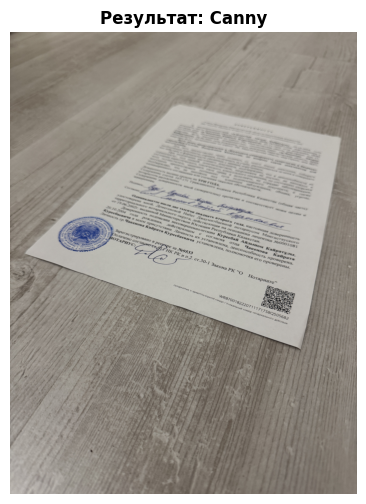

In [13]:
t_start = time.time()

edged = cv2.Canny(blurred, 50, 150)


kernel = np.ones((3, 3), np.uint8)
edged = cv2.dilate(edged, kernel, iterations=1)

show_image(edged, "Улучшенные границы (Canny)")


contours, _ = cv2.findContours(edged.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
contours = sorted(contours, key=cv2.contourArea, reverse=True)[:10]

document_contour_canny = None

for c in contours:
    perimeter = cv2.arcLength(c, True)
    approx = cv2.approxPolyDP(c, 0.02 * perimeter, True)

    if len(approx) == 4 and cv2.contourArea(c) > 10000:
        document_contour_canny = approx
        break

t_canny_total = (time.time() - t_start) * 1000
print(f"Время выполнения метода Canny и поиск контуров: {t_canny_total:.2f} мс")

output_image_canny = image.copy()
if document_contour_canny is not None:
    cv2.drawContours(output_image_canny, [document_contour_canny], -1, (0, 255, 0), 10)
    print("Canny: Четыре угла документа найдены.")
else:
    print("Canny: Контур не найден.")

show_image(output_image_canny, "Результат: Canny")

Для более надежного разделения объекта и фона применяю метод глобальной пороговой обработки Оцу в сочетании с алгоритмом  (`approxPolyDP`). Это позволяет успешно игнорировать фон и безошибочно выделить 4 угла листа бумаги.

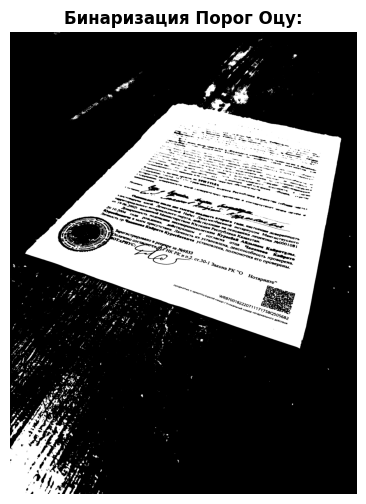

Время выполнения Оцу и контуры: 4218.44 мс
Оцу: Границы листа успешно обнаружены.


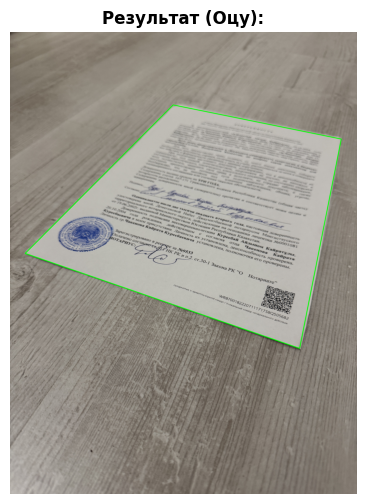

In [14]:
t_start = time.time()

gray_img = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
blurred_img = cv2.GaussianBlur(gray_img, (7, 7), 0)

# Метод Оцу
_, thresh = cv2.threshold(blurred_img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
show_image(thresh, "Бинаризация Порог Оцу:")

# Контуры на бинарном изображении
contours, _ = cv2.findContours(thresh.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
contours = sorted(contours, key=cv2.contourArea, reverse=True)

document_contour = None

for c in contours:
    perimeter = cv2.arcLength(c, True)
    approx = cv2.approxPolyDP(c, 0.02 * perimeter, True)

    if len(approx) == 4 and cv2.contourArea(c) > 5000:
        document_contour = approx
        break

t_otsu_total = (time.time() - t_start) * 1000
print(f"Время выполнения Оцу и контуры: {t_otsu_total:.2f} мс")

# Рисуем результат
output_image = image.copy()
if document_contour is not None:
    cv2.drawContours(output_image, [document_contour], -1, (0, 255, 0), 10)
    print("Оцу: Границы листа успешно обнаружены.")
else:
    print("Контур не найден.")
    if len(contours) > 0:
        rect = cv2.minAreaRect(contours[0])
        box = cv2.boxPoints(rect)
        document_contour = np.int32(box)
        cv2.drawContours(output_image, [document_contour], -1, (0, 255, 0), 10)

show_image(output_image, "Результат (Оцу):")

На финальном этапе выпрямляю найденный четырехугольник в строгие пропорции стандарта А4 (`warpPerspective`) и применяю адаптивную пороговую фильтрацию для получения контрастного, чистого документа с четким текстом и печатями. Также здесь фиксируется время выполнения  каждого шага.

Время коррекции перспективы и бинаризации: 202.43 мс
 СУММАРНОЕ ВРЕМЯ ПАЙПЛАЙНА: 4475.42 мс


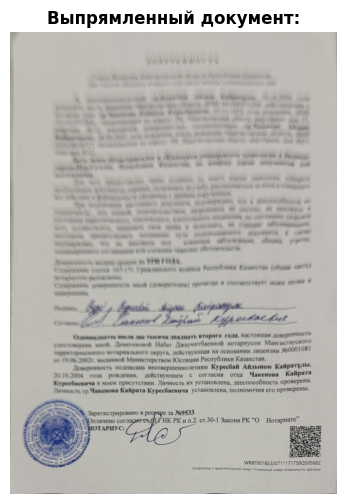

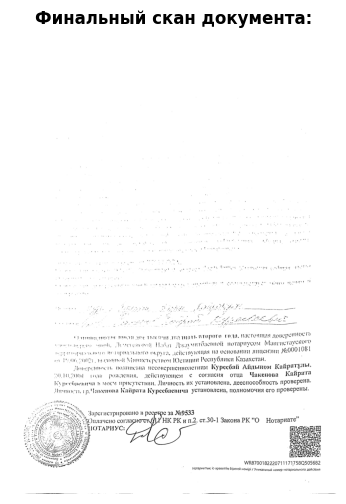

In [15]:
t_start = time.time()

def order_points(pts):
    rect = np.zeros((4, 2), dtype=np.float32)
    s = pts.sum(axis=1)
    rect[0] = pts[np.argmin(s)]
    rect[2] = pts[np.argmax(s)]
    diff = np.diff(pts, axis=1)
    rect[1] = pts[np.argmin(diff)]
    rect[3] = pts[np.argmax(diff)]
    return rect

def four_point_transform_A4(image, pts):
    rect = order_points(pts.reshape(4, 2))
    (tl, tr, br, bl) = rect

    widthA = np.sqrt(((br[0] - bl[0]) ** 2) + ((br[1] - bl[1]) ** 2))
    widthB = np.sqrt(((tr[0] - tl[0]) ** 2) + ((tr[1] - tl[1]) ** 2))
    maxWidth = max(int(widthA), int(widthB))

    heightA = np.sqrt((tr[0] - br[0]) ** 2 + (tr[1] - br[1]) ** 2)
    heightB = np.sqrt((tl[0] - bl[0]) ** 2 + (tl[1] - bl[1]) ** 2)
    maxHeight = max(int(heightA), int(heightB))

    if maxHeight < maxWidth:
        maxWidth, maxHeight = maxHeight, maxWidth
    maxHeight = int(maxWidth * 1.414)

    dst = np.float32([
        [0, 0],
        [maxWidth - 1, 0],
        [maxWidth - 1, maxHeight - 1],
        [0, maxHeight - 1]
    ])

    M = cv2.getPerspectiveTransform(rect, dst)
    return cv2.warpPerspective(image, M, (maxWidth, maxHeight))

if document_contour is not None:
    # Перспективное преобразование
    scan_result = four_point_transform_A4(image, document_contour)

    # Финальная адаптивная бинаризация
    gray_scan = cv2.cvtColor(scan_result, cv2.COLOR_BGR2GRAY)
    final_scan = cv2.adaptiveThreshold(
        gray_scan, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY, 15, 11
    )

    t_warp_scan = (time.time() - t_start) * 1000
    print(f"Время коррекции перспективы и бинаризации: {t_warp_scan:.2f} мс")

    # Общий итог
    total_pipeline_time = t_blur + t_otsu_total + t_warp_scan
    print(f" СУММАРНОЕ ВРЕМЯ ПАЙПЛАЙНА: {total_pipeline_time:.2f} мс")

    show_image(scan_result, "Выпрямленный документ:")
    show_image(final_scan, "Финальный скан документа:")

else:
    print("Ошибка: Переменная 'document_contour' не найдена.")